

---



---


# Multi-class Semantic Segmentation on the PanNuke Histological Dataset
---



---



## % Libraries - Imports

In [1]:
# install segmentation-models-pytorch if it is not already available
# (Colab does not have it preinstalled; a local venv already includes it via pyproject.toml)
try:
    import segmentation_models_pytorch
except ImportError:
    !pip install segmentation-models-pytorch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 5.1 MB/s eta 0:00:00


In [2]:
import os
import random
import sys

import numpy as np
import torch
from torch.utils.data import DataLoader, Subset

import matplotlib
import matplotlib.pyplot as plt
import torchvision

In [3]:
# double-check the installed versions of the key libraries
print(f"numpy version:        {np.__version__}")
print(f"torch version:         {torch.__version__}")
print(f"torchvision version:   {torchvision.__version__}")
print(f"matplotlib version:    {matplotlib.__version__}")


numpy version:        2.1.3
torch version:         2.11.0+cu130
torchvision version:   0.26.0+cu130
matplotlib version:    3.10.0


## % Mount Google drive

In [ ]:
# mount Google Drive when running on Colab, otherwise use the local project folder
try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = ""
except ImportError:
    PROJECT_DIR = os.getcwd()   # running locally, from the project folder

print("PROJECT_DIR:", PROJECT_DIR)

In [5]:
# import the functions/classes that were moved into .py files
# (the .py files are next to data_root/ in the project folder)
sys.path.insert(0, PROJECT_DIR)

from pannuke_dataset import *
from pannuke_utils import *
from model_pretrained_unet_plusplus import create_pretrained_unetplusplus

### --- Load data - PanNuke dataset - Fold1 ---
PanNuke Dataset for Nuclei Instance Segmentation and Classification - https://huggingface.co/datasets/RationAI/PanNuke

In [6]:
# load the PanNuke Fold1 images and their per-category instance masks
images = np.load(PROJECT_DIR + "/data_root/images.npy")
masks = np.load(PROJECT_DIR + "/data_root/masks.npy")

# sanity-check the loaded array shapes and dtypes
print("images shape:", images.shape, "images dtype:", images.dtype)
print("masks shape:", masks.shape, "masks dtype:", masks.dtype)

images shape: (2656, 256, 256, 3) images dtype: float64
masks shape: (2656, 256, 256, 6) masks dtype: float64


# UNet++ with pretrained ResNet34 encoder
1. Encoder = ResNet34 (pretrained)
2. Decoder = UNet++ architecture (trained from scratch)

## % CONFIGURATION + Parameters setting + Data preparation for model training

In [7]:
# --- CONFIGURATION ---
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
BATCH_SIZE = 16
LEARNING_RATE = 0.0001
NUM_EPOCHS = 200
VAL_SPLIT = 0.15
TEST_SPLIT = 0.15
CHECKPOINT_DIR = PROJECT_DIR + '/data_root/checkpoints_UNet++_pretrained'

# fix all RNG seeds so the run is reproducible
SEED = 54
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
np.random.seed(SEED)
random.seed(SEED)
torch.backends.cudnn.deterministic = True

# make sure the checkpoint folder exists
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

### --- Training/Validation/Test data creation ---

In [8]:
# rebuild the dataset for the pretrained UNet++ run (augmentation enabled)
# two views of the same data: augmented for training, clean for validation/test
# the pretrained ResNet34 encoder expects ImageNet-normalized input
train_full_dataset = PanNukeDataset(images, masks, augment=True, normalization="imagenet")
eval_full_dataset  = PanNukeDataset(images, masks, augment=False, normalization="imagenet")

Dataset ready: 2656 samples
Dataset ready: 2656 samples


In [9]:
# re-split into train/val/test (fresh shuffle, same ratios as before)
n = len(train_full_dataset)
indices = list(range(n))
# shuffle before splitting so train/val/test are randomly sampled
random.shuffle(indices)

# compute split sizes from the configured ratios
n_val = int(n * VAL_SPLIT)
n_test = int(n * TEST_SPLIT)

# slice the shuffled indices into val / test / train
val_idx = indices[:n_val]
test_idx = indices[n_val:n_val + n_test]
train_idx = indices[n_val + n_test:]

print(f"Train: {len(train_idx)} | Val: {len(val_idx)} | Test: {len(test_idx)}")

Train: 1860 | Val: 398 | Test: 398


In [10]:
# wrap each split's indices into a Subset, then into a DataLoader for batching
# only the training split reads from the augmented dataset
train_dataset = Subset(train_full_dataset, train_idx)
val_dataset = Subset(eval_full_dataset, val_idx)
test_dataset = Subset(eval_full_dataset, test_idx)

# only shuffle the training loader; keep val/test order fixed
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

### --- Model + optimizer - PreTrained model ---

In [11]:
# Model definition (moved to model_pretrained_unet_plusplus.py)
model_pretrained = create_pretrained_unetplusplus()

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

In [12]:
model_pretrained_UNet = model_pretrained.to(DEVICE)

# Optimizer
optimizer_pretrained = torch.optim.AdamW(model_pretrained.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)

### --- Train Pretrained UNet++ ---

In [ ]:
# training loop for the baseline SimpleUNet
print("Starting Training...")

# track loss/Dice history and keep the best checkpoint by validation Dice
history = {"train_loss": [], "train_dice": [], "val_loss": [], "val_dice": []}
best_val_dice = 0.0

for epoch in range(NUM_EPOCHS):
    # 1. Train
    train_loss, train_dice = train_model(model = model_pretrained_UNet,
                             training_data = train_loader,
                             num_classes=6,
                             optimizer = optimizer_pretrained)

    # 2. Validate
    val_loss, val_dice = validate_model(model = model_pretrained_UNet,
                                        validation_data = val_loader,
                                        num_classes=6)

    # 3. Store for plotting later
    history["train_loss"].append(train_loss)
    history["train_dice"].append(train_dice)
    history["val_loss"].append(val_loss)
    history["val_dice"].append(val_dice)

    # 4. Print Stats
    print(f"Epoch [{epoch+1}/{NUM_EPOCHS}] "
          f"||| Train Loss: {train_loss:.4f} | Train Dice: {train_dice:.4f} "
          f"||| Val Loss: {val_loss:.4f} | Val Dice: {val_dice:.4f}")

    # checkpoint whenever validation Dice improves
    if val_dice > best_val_dice:
        best_val_dice = val_dice
        checkpoint_path = os.path.join(CHECKPOINT_DIR, f'PreTrained_UNetPlusPlus_{epoch}.pth')
        torch.save({
            'epoch': epoch + 1,
            'model_state_dict': model_pretrained_UNet.state_dict(),
            'optimizer_state_dict': optimizer_pretrained.state_dict(),
            'val_dice': val_dice
        }, checkpoint_path)
        print(f"   >>> Improvement! Saving model (Dice: {val_dice:.4f})")

print(f"\nTraining Complete. Best Validation Dice: {best_val_dice:.4f}")

Starting Training...
Epoch [1/200] ||| Train Loss: 0.7596 | Train Dice: 0.2949 ||| Val Loss: 0.6838 | Val Dice: 0.3795
   >>> Improvement! Saving model (Dice: 0.3795)
Epoch [2/200] ||| Train Loss: 0.6392 | Train Dice: 0.4312 ||| Val Loss: 0.6091 | Val Dice: 0.4477
   >>> Improvement! Saving model (Dice: 0.4477)
Epoch [3/200] ||| Train Loss: 0.5624 | Train Dice: 0.4887 ||| Val Loss: 0.5322 | Val Dice: 0.5171
   >>> Improvement! Saving model (Dice: 0.5171)
Epoch [4/200] ||| Train Loss: 0.5233 | Train Dice: 0.5096 ||| Val Loss: 0.5226 | Val Dice: 0.5056
Epoch [5/200] ||| Train Loss: 0.5005 | Train Dice: 0.5189 ||| Val Loss: 0.4867 | Val Dice: 0.5308
   >>> Improvement! Saving model (Dice: 0.5308)
Epoch [6/200] ||| Train Loss: 0.4798 | Train Dice: 0.5344 ||| Val Loss: 0.4845 | Val Dice: 0.5256
Epoch [7/200] ||| Train Loss: 0.4746 | Train Dice: 0.5359 ||| Val Loss: 0.4985 | Val Dice: 0.5098
Epoch [8/200] ||| Train Loss: 0.4669 | Train Dice: 0.5426 ||| Val Loss: 0.4580 | Val Dice: 0.5528
   

### --- Plot Progress ---

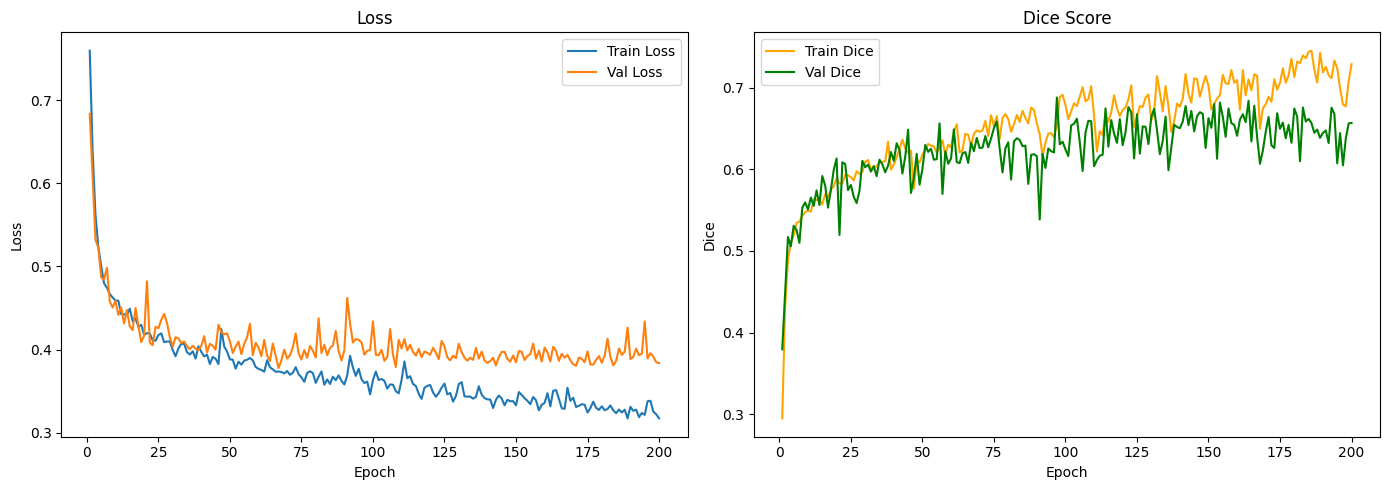

In [ ]:
# plot loss/Dice curves for this run
epochs = range(1, len(history["train_loss"]) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Loss plot
ax1.plot(epochs, history["train_loss"], label="Train Loss")
ax1.plot(epochs, history["val_loss"], label="Val Loss")
ax1.set_title("Loss")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.legend()

# Dice plot
ax2.plot(epochs, history["train_dice"], label="Train Dice", color="orange")
ax2.plot(epochs, history["val_dice"], label="Val Dice", color="green")
ax2.set_title("Dice Score")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Dice")
ax2.legend()

plt.tight_layout()
plt.show()

### --- Conclusion ---

After finishing the training of the pretrained UNet++ model we can see the following:

**Loss graph:**
*   Train Loss decreases with small fluctuations (from ~0.76 to ~0.32)
*   Val Loss drops quickly in the first ~20 epochs (from ~0.68 to ~0.41), then it hardly improves (around 0.39 after epoch 60) and fluctuates more than Train Loss
*   A growing gap between Train and Val Loss is visible from epoch 50 onwards, indicating overfitting as the model continues to train

---
**Dice graph:**
*   Both Train and Val Dice increase rapidly in the first 25 epochs - as expected (Val Dice is ~0.55 already at epoch 8)
*   After epoch 50 the improvement slows down significantly
*   A consistent increasing gap between Train Dice and Val Dice is visible: it grows from about 0.01 (epochs 20 - 60) to about 0.04 (epochs 140 - 160) and about 0.07 (epochs 180 - 200), where Train Dice is ~0.72 and Val Dice ~0.65, indicating moderate overfitting as continuing to train the model.

---

With the above configuration, the pretrained UNet++ model could reach its best result without overfitting at **Epoch [76/200]**, where the results were the following:
*   Train Loss: 0.3612 | Train Dice: 0.6649 ||| Val Loss: 0.3995 | Val Dice: 0.6584

---
**At Epoch 76:**
*   => no significant overfitting (the Train-Val Dice gap is only ~0.01, it grows clearly after epoch ~80)
*   => the Val Dice fluctuates from epoch to epoch, but this value is the top of a fairly stable stretch , not an isolated spike
*   => later epochs reach a higher Val Dice (up to 0.6878), but only as single peaks with a growing Train-Val gap


*Comparing UNet++ with pretrained UNet++, the introduction of a pretrained ResNet34 encoder brought a clear improvement — Val Dice increased from 0.5620 (epoch 143) to 0.6584 (epoch 76), and even the typical Val Dice of the later epochs (~0.65) is clearly above the ~0.54 - 0.55 of UNet++. The pretrained encoder already knows edges, textures, and shapes from 1.2 million ImageNet images, allowing the model to converge much faster and reach higher Dice scores. Because the overfitting is more visible here than in the previous models, further regularization techniques such as stronger dropout or additional augmentation could help and push the results even higher.*

### --- Pretrained UNet++ predictions ---

In [13]:
# reload the best UNet++ checkpoint
checkpoint = torch.load(
    PROJECT_DIR + "/data_root/checkpoints_UNet++_pretrained/PreTrained_UNetPlusPlus_75.pth",
    map_location=DEVICE,
    weights_only=False
)

#Load the weights into the model
model_pretrained.load_state_dict(checkpoint["model_state_dict"])

print(f"Model loaded from epoch {checkpoint['epoch']}")
print(f"Best Val Dice: {checkpoint['val_dice']:.4f}")


Model loaded from epoch 76
Best Val Dice: 0.6584


### --- Test set evaluation ---

In [14]:
# quantitative evaluation on the held-out test set
test_loss, test_dice = validate_model(model=model_pretrained, validation_data=test_loader, num_classes=6)
print(f"Test Loss: {test_loss:.4f} | Test Dice: {test_dice:.4f}")

Test Loss: 0.4087 | Test Dice: 0.6488


In [15]:
# visualize predictions from the pretrained UNet++ model
# pass the ImageNet mean/std so the plotted images are de-normalized back to the originals
visualize_predictions(model_pretrained, test_dataset, num_images=6,
                      mean=IMAGENET_MEAN, std=IMAGENET_STD)

Output hidden; open in https://colab.research.google.com to view.